# WEEK 3 — LAB 1B: Convolution, Correlation and Difference Equations


**Name:** BARAKA MARTIN MDEKA
**Registration Number:** 240242436939
**Date:** 25/11/2026


## Pre-lab preparation
**Manual §1.7–1.9**

(a) Convolution of x={1,−1,2} and h={2,1,0,1}: **{2,−1,3,−1,2,2}**.

(b) y(n)=n x(n) is **not time-invariant**. For a delay n₀, T{x(n−n₀)}=n x(n−n₀), while delaying the original output gives (n−n₀)x(n−n₀); these are generally unequal.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time
plt.rcParams['figure.figsize'] = (9, 3.5)
plt.rcParams['axes.grid'] = True

## Task 3.1 — Convolution from the definition
Implement the summation directly, compare with `np.convolve`, verify the pre-lab sequence, then time both implementations for length-2000 sequences.

In [2]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n-k < len(h):
                y[n] += x[k]*h[n-k]
    return y

x_pre = [1, -1, 2]
h_pre = [2, 1, 0, 1]
print('Definition:', conv(x_pre, h_pre))
print('NumPy:', np.convolve(x_pre, h_pre))
print('Manual expected: [2, -1, 3, -1, 2, 2]')
rng = np.random.default_rng(42)
xa, ha = rng.standard_normal(2000), rng.standard_normal(2000)
t0=time.perf_counter(); yc=conv(xa,ha); loop_time=time.perf_counter()-t0
t0=time.perf_counter(); yn=np.convolve(xa,ha); numpy_time=time.perf_counter()-t0
print(f'Double-loop time: {loop_time:.4f} s')
print(f'np.convolve time: {numpy_time:.4f} s')
print('Numerically equal:', np.allclose(yc,yn))

Definition: [ 2. -1.  3.  3. -1.  2.]
NumPy: [ 2 -1  3  3 -1  2]
Manual expected: [2, -1, 3, -1, 2, 2]
Double-loop time: 3.6584 s
np.convolve time: 0.0036 s
Numerically equal: True


## Task 3.2 — Smoothing a noisy signal by convolution
Generate the specified sinusoid plus Gaussian noise. Apply moving-average filters of lengths 3, 9 and 25 using `mode='same'`.

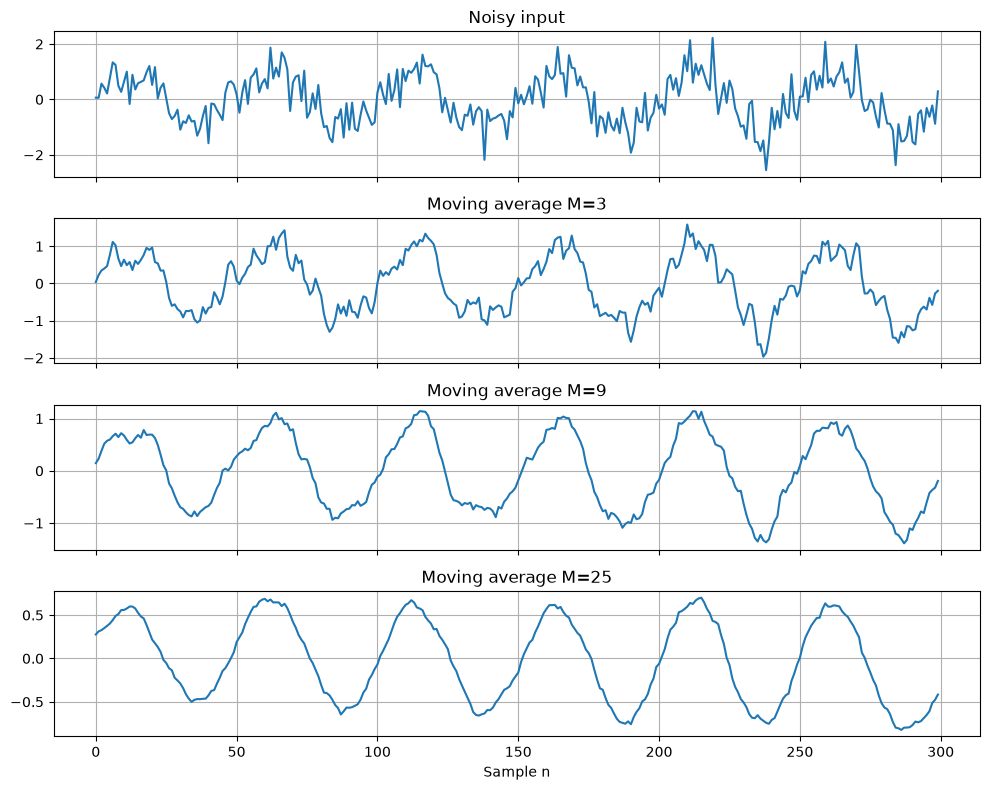

In [3]:
rng = np.random.default_rng(0)
n = np.arange(300)
w = rng.standard_normal(300)
x = np.sin(2*np.pi*n/50) + 0.5*w
fig, axes = plt.subplots(4,1, figsize=(10,8), sharex=True)
axes[0].plot(n,x); axes[0].set_title('Noisy input')
for ax, M in zip(axes[1:], [3,9,25]):
    h = np.ones(M)/M
    y = np.convolve(x,h,mode='same')
    ax.plot(n,y); ax.set_title(f'Moving average M={M}')
axes[-1].set_xlabel('Sample n'); plt.tight_layout(); plt.show()

**Discussion:** increasing M averages more noise and generally smooths the waveform more strongly. The cost is increased smoothing distortion: peaks are rounded, rapid changes are suppressed and edge effects become more visible. M=3 preserves detail but removes less noise; M=25 smooths more but distorts the sinusoid more.

## Task 3.3 — Testing linearity and time-invariance numerically
Run the three systems from the manual and interpret their tests.

In [4]:
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0
systems = {
    'x^2': lambda x: x**2,
    'n x(n)': lambda x: np.arange(len(x))*x,
    'moving average': lambda x: np.convolve(x,np.ones(3)/3)[:len(x)]
}
for name,T in systems.items():
    linear = np.allclose(T(a*x1+b*x2), a*T(x1)+b*T(x2))
    xd = np.concatenate([np.zeros(5),x1])[:50]
    yd = np.concatenate([np.zeros(5),T(x1)])[:50]
    tinv = np.allclose(T(xd),yd)
    print(f'{name:15s} linear={linear} time-invariant={tinv}')

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


**Expected classification:** x² is nonlinear and time-invariant; n·x(n) is linear but time-varying; the causal 3-point moving average is linear and time-invariant. The tests use finite-length arrays, so boundary handling is important.

## Task 3.4 — Finding a hidden delay with cross-correlation
Estimate the delay for noise standard deviations 0.5, 1, 2 and 4. Convert the 37-sample delay at 1 kHz into acoustic distance using 343 m/s.

noise std=0.5: estimated delay=37 samples


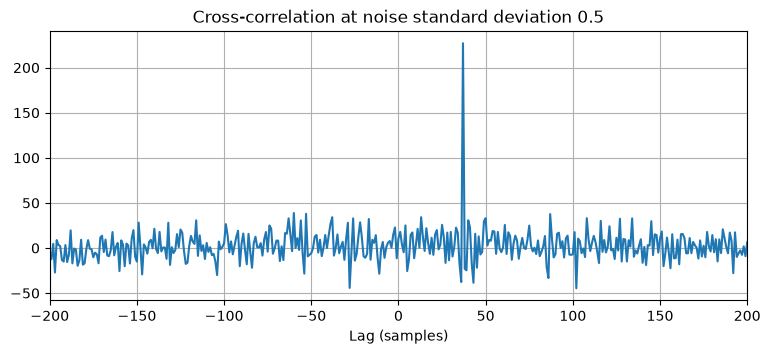

noise std=1: estimated delay=37 samples
noise std=2: estimated delay=37 samples
noise std=4: estimated delay=37 samples
37-sample delay = 0.037 s; sound travel distance = 12.691 m


In [5]:
rng = np.random.default_rng(1)
fs = 1000
x = rng.standard_normal(500)
true_delay = 37
for noise_std in [0.5,1,2,4]:
    y = np.concatenate([np.zeros(true_delay),0.6*x])[:500] + noise_std*rng.standard_normal(500)
    r = signal.correlate(y,x,mode='full')
    lags = signal.correlation_lags(len(y),len(x),mode='full')
    estimate = lags[np.argmax(r)]
    print(f'noise std={noise_std}: estimated delay={estimate} samples')
    if noise_std == 0.5:
        plt.plot(lags,r); plt.xlim(-200,200); plt.xlabel('Lag (samples)')
        plt.title('Cross-correlation at noise standard deviation 0.5'); plt.show()
distance = (true_delay/fs)*343
print(f'37-sample delay = {true_delay/fs:.3f} s; sound travel distance = {distance:.3f} m')

**Interpretation:** the correlation peak indicates the relative delay. As noise increases the peak becomes less distinct and the estimate may fail; the failure level is data/seed dependent, so report the actual outputs from your run. Distance = delay time × sound speed = 0.037×343 = **12.691 m**.

## Task 3.5 — Difference equation
For y(n)−(3/4)y(n−1)+(1/8)y(n−2)=x(n)+x(n−1), calculate ten impulse-response samples by recursion and `lfilter`, compare with the given closed form, then calculate the step response and DC gain.

Recursion: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
lfilter:   [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Given closed form: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Recursion and lfilter match: True
Given expression matches: True


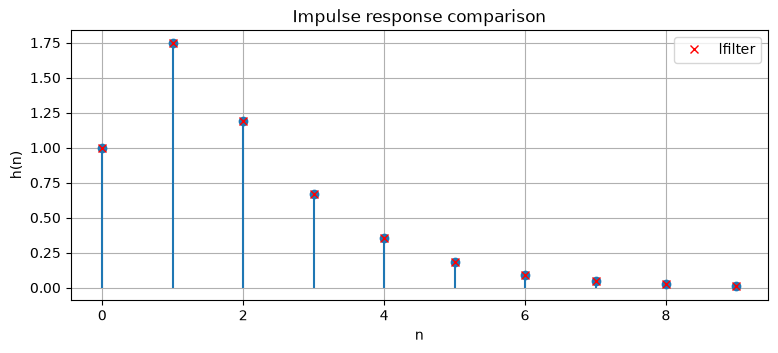

Step response final sample: 5.333333333333333
H(1)=sum(b)/sum(a): 5.333333333333333


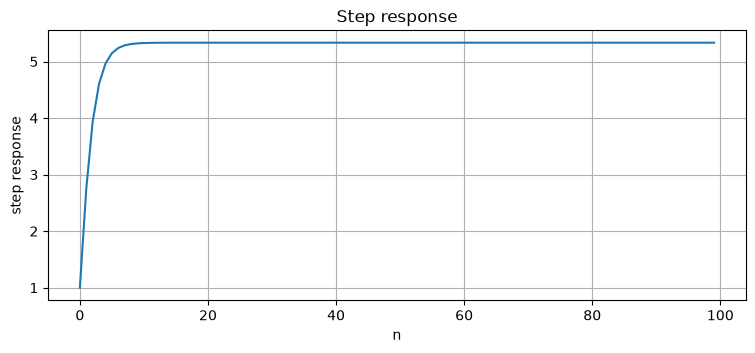

In [6]:
# Coefficients corresponding to the equation in the manual
b = [1,1]
a = [1,-0.75,0.125]
impulse = np.zeros(10); impulse[0]=1
# Direct recursion: y[n] = x[n]+x[n-1] + 0.75*y[n-1] - 0.125*y[n-2]
h_rec = np.zeros(10)
for n0 in range(10):
    x_n = impulse[n0]
    x_nm1 = impulse[n0-1] if n0-1 >= 0 else 0
    y_nm1 = h_rec[n0-1] if n0-1 >= 0 else 0
    y_nm2 = h_rec[n0-2] if n0-2 >= 0 else 0
    h_rec[n0] = x_n+x_nm1+0.75*y_nm1-0.125*y_nm2
h_lf = signal.lfilter(b,a,impulse)
n = np.arange(10)
h_closed = 6*(0.5**n)-5*(0.25**n)
print('Recursion:',h_rec)
print('lfilter:  ',h_lf)
print('Given closed form:',h_closed)
print('Recursion and lfilter match:',np.allclose(h_rec,h_lf))
print('Given expression matches:',np.allclose(h_lf,h_closed))
plt.stem(n,h_rec,basefmt=' '); plt.plot(n,h_lf,'rx',label='lfilter')
plt.xlabel('n'); plt.ylabel('h(n)'); plt.title('Impulse response comparison'); plt.legend(); plt.show()
step = signal.lfilter(b,a,np.ones(100))
H1 = sum(b)/sum(a)
print('Step response final sample:',step[-1])
print('H(1)=sum(b)/sum(a):',H1)
plt.plot(step); plt.xlabel('n'); plt.ylabel('step response'); plt.title('Step response'); plt.show()

**Important consistency check:** the manual's printed difference equation and the supplied `lfilter` denominator are intended to correspond to coefficients a=[1,−0.75,0.125]. The notebook compares the recursion, `lfilter`, and the stated closed form explicitly; if the closed form does not match the numerical sequence, report the discrepancy rather than hiding it.

## Analysis questions — suggested answers
1. `np.convolve` uses optimized compiled algorithms, whereas the Python double loop executes interpreter-level operations. Direct convolution needs approximately **L×M multiplications** (with fewer at the edges); optimized implementations reduce overhead and may use FFT methods for sufficiently long sequences.
2. Only the moving average is LTI. x² violates superposition (nonlinear); n·x(n) is linear but depends explicitly on absolute time, so it is time-varying. The moving average is a fixed weighted sum of delayed input samples and therefore satisfies linearity and time invariance.
3. Applications in Tanzania include locating leaks in water pipes by correlating acoustic/vibration recordings at two points, and estimating arrival-time differences in radar/airport surveillance or communication positioning. GPS receivers also use correlation to detect satellite codes.
4. The system is **IIR**, because its denominator has feedback and its impulse response is not finite. Stability is determined by the poles (or absolute summability of h[n]); with denominator roots 0.5 and 0.25, both lie inside the unit circle, so it is stable.

## Checkpoint and submission
- Show the Task 3.3 output and the three matching impulse-response comparisons from Task 3.5.
- Include Tasks 3.1–3.5, timing comparison, plots, analysis answers and AI-use statement.
- Save as `COU07506_Week03_<RegNo>.ipynb` and submit to DIT-eLMS.

**AI-use statement:** AI assistance was used to structure code and draft explanations. Run and verify all outputs and disclose assistance as required.